# SAM-6D + FoundationPose — Photoneo PhoXi 3D M

Multi-object 6D pose estimation using the **Photoneo PhoXi 3D M** (blue) camera.

**Pipeline:**
1. **Init** — loads SAM + DINOv2 (ISM) and PEM, renders CAD templates, computes reference descriptors for all 3 models
2. **Load** — reads RGBD data and camera intrinsics from a `.praw` file via `phoxi_api` (or falls back to pre-extracted TIF files)
3. **Forward** — detects all 3 object types simultaneously, returning 6DoF poses, masks, and confidence scores
4. **Refine** — FoundationPose refines each detection's pose using iterative RGB-D re-rendering

**Prerequisites:**
- `pip install phoxi-api` (already installed in cnos2)
- PhoXi Control running (`/usr/bin/PhoXiControl` — it runs as a background service even without the GUI open)
- The `.praw` file is attached as a virtual file camera automatically via `phoxi_api.attach_file_camera()`
- If PhoXi Control is unavailable, the fallback loads from pre-extracted TIF files — fill in `FX/FY/CX/CY` from PhoXi Control → Camera → Calibration

**Depth convention:** PhoXi DepthMap is in **millimetres** — `depth_scale = 1.0`.

Templates are cached in `sam6d_templates_*/` and skipped on re-runs.

In [ ]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt

/home/joon/.virtualenvs/cnos2/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


K:
[[2.82421655e+03 0.00000000e+00 1.25717993e+03]
 [0.00000000e+00 2.82397192e+03 1.00944037e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
RGB:   (2064, 2472, 3)
Depth: (2064, 2472)  range 0–825 mm


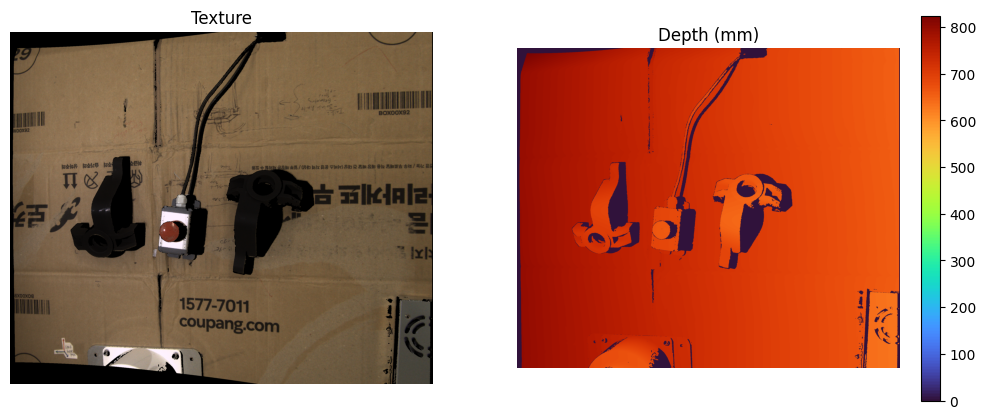

In [2]:
DEPTH_SCALE = 1.0  # PhoXi DepthMap is already in mm

from phoxi_api import PhoXiControl, PhoXiDevice

phc = PhoXiControl()
device_id = phc.get_device_list(refresh=True)[0]["id"]

with phc.connect(device_id) as device:
    device.set_trigger_mode(PhoXiDevice.TriggerMode.SOFTWARE)
    device.set_frame_settings({"DepthMap": True, "Texture": True})
    device.start_acquisition()
    frame = device.get_frame(frame_id=device.trigger_frame(wait_grabbing_end=True), timeout_ms=60_000)

K = np.array(frame.Info["CameraMatrix"], dtype=np.float32).reshape(3, 3)
depth = np.array(frame.DepthMap, dtype=np.float32).squeeze()
texture = np.array(frame.Texture).squeeze()
rgb = np.stack([texture] * 3, axis=-1) if texture.ndim == 2 else texture
rgb = (rgb / rgb.max() * 255).clip(0, 255).astype(np.uint8)

print(f"K:\n{K}")
print(f"RGB:   {rgb.shape}")
print(f"Depth: {depth.shape}  range {depth.min():.0f}–{depth.max():.0f} mm")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb); axes[0].set_title("Texture"); axes[0].axis("off")
im = axes[1].imshow(depth, cmap="turbo"); axes[1].set_title("Depth (mm)"); axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.show()
